# Digital Image Processing project
Done by:
*   Souvik Ahmed (203014004)
*   Muhesena Nasiha Syeda (203014015)
*   Sanjida Tasnim Oishi (211014014)

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
# Specify the filename to take as input. Make sure the file is uploaded to this google collab
image_path = input("Enter the filename of the image: ")
image = Image.open(image_path).convert("L")  # Convert to grayscale
image_array = np.array(image)

Enter the filename of the image: image4.jpg


In [ ]:
# Take the upper bound for white intensity as input, to control for extremely bright sections in output
upper_bound = int(input("Enter the upper bound for white intensity: "))

Enter the upper bound for white intensity: 255


In [ ]:
# Flatten the image to 1D, since spatial aspect of image does not matter here
flat_image = image_array.flatten()

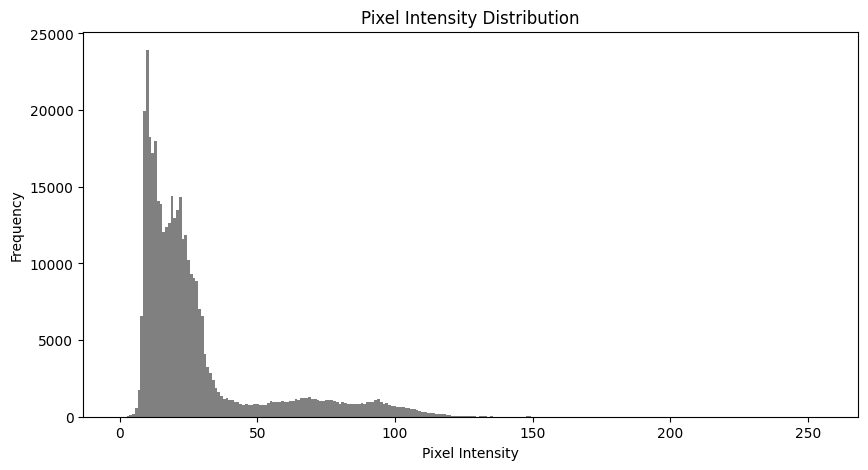

In [ ]:
# Calculate the histogram manually to understand the distribution of pixel values
histogram = np.zeros(256, dtype=int) #basically, this is 256 bar graphs that count the number of times an x brightness value appears in the image. For example, the pixel brightness value of 120 might appear 46 times throughout the image.
for pixel in flat_image:
    histogram[pixel] += 1

# Plot the histogram found
plt.figure(figsize=(10, 5))
plt.bar(range(256), histogram, color='gray', width=1.0)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Calculate the cumulative distribution function (CDF)
cdf = np.zeros_like(histogram, dtype=float)
sum_hist = 0
for i in range(len(histogram)):
    sum_hist += histogram[i]
    cdf[i] = sum_hist

In [ ]:
# Normalize the CDF to the range of 0 to the upper bound that was given as input earlier
cdf_min = cdf[np.nonzero(cdf)[0][0]]  # First non-zero value of the CDF
cdf_normalized = (cdf - cdf_min) / (cdf[-1] - cdf_min) * upper_bound
cdf_normalized = cdf_normalized.astype(np.uint8)

In [ ]:
# Map the original pixel values to equalized values
equalized_image = np.zeros_like(flat_image, dtype=np.uint8)
for i in range(len(flat_image)):
    equalized_image[i] = cdf_normalized[flat_image[i]]

In [ ]:
# Reshape back to the original image 2d dimension, so that it can be viewed as a proper image
equalized_image = equalized_image.reshape(image_array.shape)

In [ ]:
# Plot the histogram after normalization
normalized_histogram = np.zeros(256, dtype=int)
for pixel in equalized_image.flatten():
    normalized_histogram[pixel] += 1

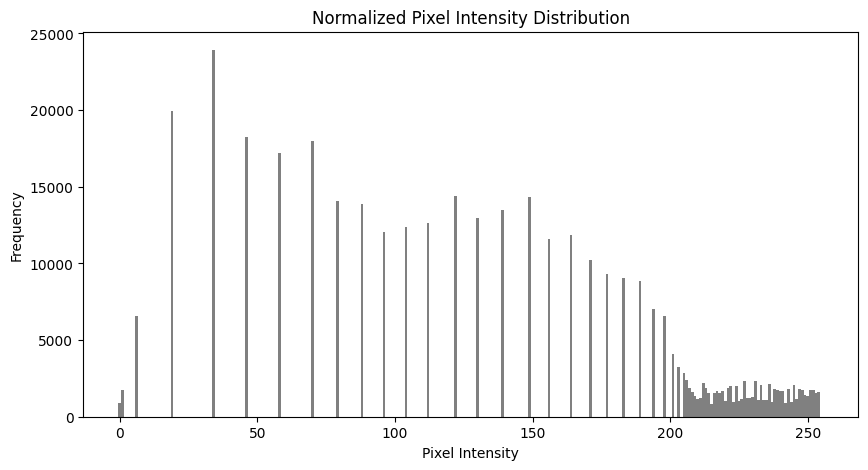

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(range(256), normalized_histogram, color='gray', width=1.0)
plt.title("Normalized Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Save the before and after images
Image.fromarray(image_array).save("before_equalization.jpg")
Image.fromarray(equalized_image).save("after_equalization.jpg")

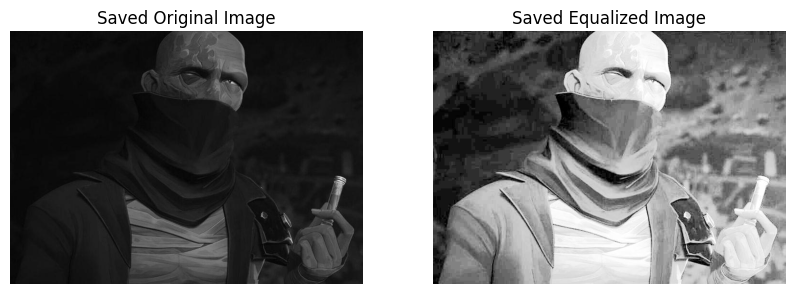

In [ ]:
# Display the saved images
before_image = Image.open("before_equalization.jpg")
after_image = Image.open("after_equalization.jpg")
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Saved Original Image")
plt.imshow(before_image, cmap="gray")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.title("Saved Equalized Image")
plt.imshow(after_image, cmap="gray")
plt.axis("off")
plt.show()

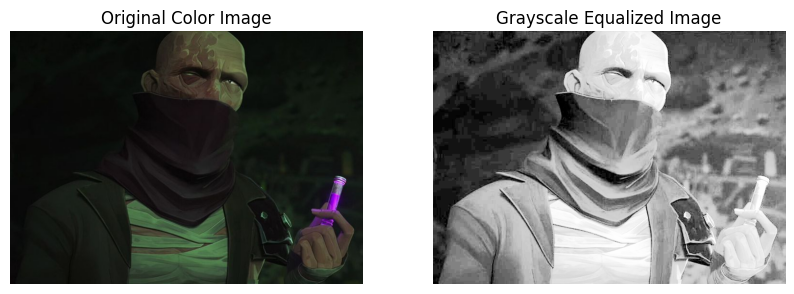

In [ ]:
# Load the original (non-grayscale) image
original_image = Image.open(image_path)

# Display the original color image and the grayscale equalized image side by side
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Original Color Image")
plt.imshow(original_image)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Grayscale Equalized Image")
plt.imshow(equalized_image, cmap="gray")
plt.axis("off")
plt.show()